In [122]:
%load_ext autoreload
%autoreload 2

from fsl_mrs.utils.synthetic import synthetic_from_dynamic as syn
from fsl_mrs.utils import mrs_io
from fsl_mrs.utils import plotting as splot

import matplotlib.pyplot as plt
import pandas as pd
import re
import numpy as np
basis = mrs_io.read_basis('basis')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load the two direction files 

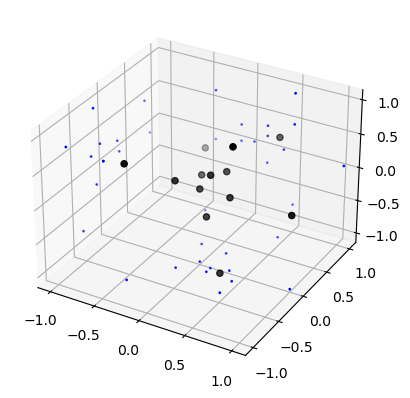

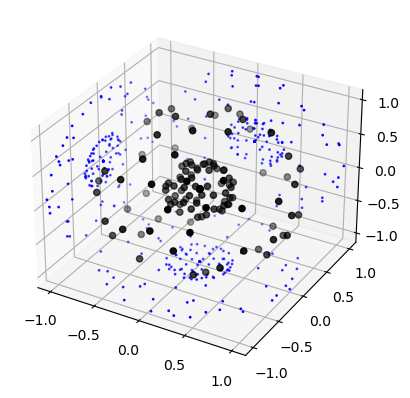

In [123]:
def load_file(file_path, max_bvalue=3, plot=True):
    bvecs = []
    bvptrn = re.compile(r'Vector\[\d+\] = \((.*)\)')
    with open(file_path) as bv:
        for line in bv.readlines():
            match = bvptrn.match(line)
            if match:
                bvecs.append([float(x) for x in match[1].split(',')])
    bvecs = np.asarray(bvecs)

    if plot:
        fig = plt.figure()
        ax = fig.add_subplot(projection='3d')
        ax.scatter(bvecs[:,0], bvecs[:,1], -1.1 + 0*bvecs[:,2], c='b', s=1)
        ax.scatter(bvecs[:,0], 1.1 + 0*bvecs[:,1], bvecs[:,2], c='b', s=1)
        ax.scatter(-1.1 + 0*bvecs[:,0], bvecs[:,1], bvecs[:,2], c='b', s=1)
        ax.scatter(bvecs[:,0], bvecs[:,1], bvecs[:,2], c='k')
        ax.set_xlim([-1.1, 1.1])
        ax.set_ylim([-1.1, 1.1])
        ax.set_zlim([-1.1, 1.1])
        plt.show()

    return bvecs * max_bvalue

b_6_dir =load_file('b_1000_3000_6dir', max_bvalue=3, plot=True)
b_60_dir =load_file('b_1000_3000_60dir', max_bvalue=3, plot=True)



### Generate random tensors, one for each metabolite

In [124]:
def gen_random_tensor(adc_mean, adc_sd):
    rng = np.random.default_rng()
    adc = 0
    while adc <= 0:
        adc = adc_mean + rng.standard_normal(1) * adc_sd
    diffusivity = 3 * adc *rng.dirichlet(np.ones(3), size=1)
    diffusivity = np.diag(diffusivity.squeeze())
    # print(np.diag(diffusivity).mean())

    V, _ = np.linalg.qr(rng.standard_normal((3,3)))

    # print(V)
    # print((V**2).sum(axis=0))
    # print(V.dot(V.T))

    return V @ diffusivity @ V.T

def gen_metabolite_tensor_params(metab):
    tensor = gen_random_tensor(0.22, 0.02)
    return {
       f'conc_{metab}_c_Dxx': tensor[0, 0],
       f'conc_{metab}_c_Dyy': tensor[1, 1],
       f'conc_{metab}_c_Dzz': tensor[2, 2],
       f'conc_{metab}_c_Dxy': tensor[0, 1],
       f'conc_{metab}_c_Dxz': tensor[0, 2],
       f'conc_{metab}_c_Dyz': tensor[1, 2]}

print(gen_metabolite_tensor_params('NAA'))

{'conc_NAA_c_Dxx': 0.19046483631938563, 'conc_NAA_c_Dyy': 0.10859786177841006, 'conc_NAA_c_Dzz': 0.339682137986827, 'conc_NAA_c_Dxy': -0.04872716239526919, 'conc_NAA_c_Dxz': -0.15772409591402214, 'conc_NAA_c_Dyz': 0.09021383482945267}


### Generate data for each set of directions and the precomputed random tensors

Noise variance for the 6 direction data should be 10 times less than the 60 direction, to match total experiment time.

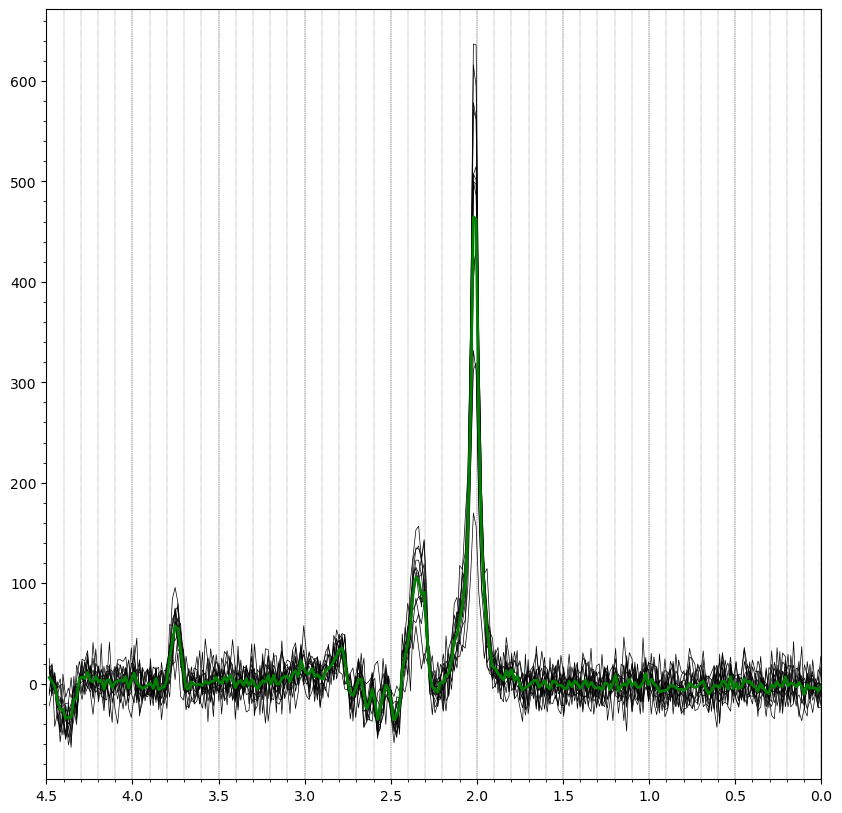

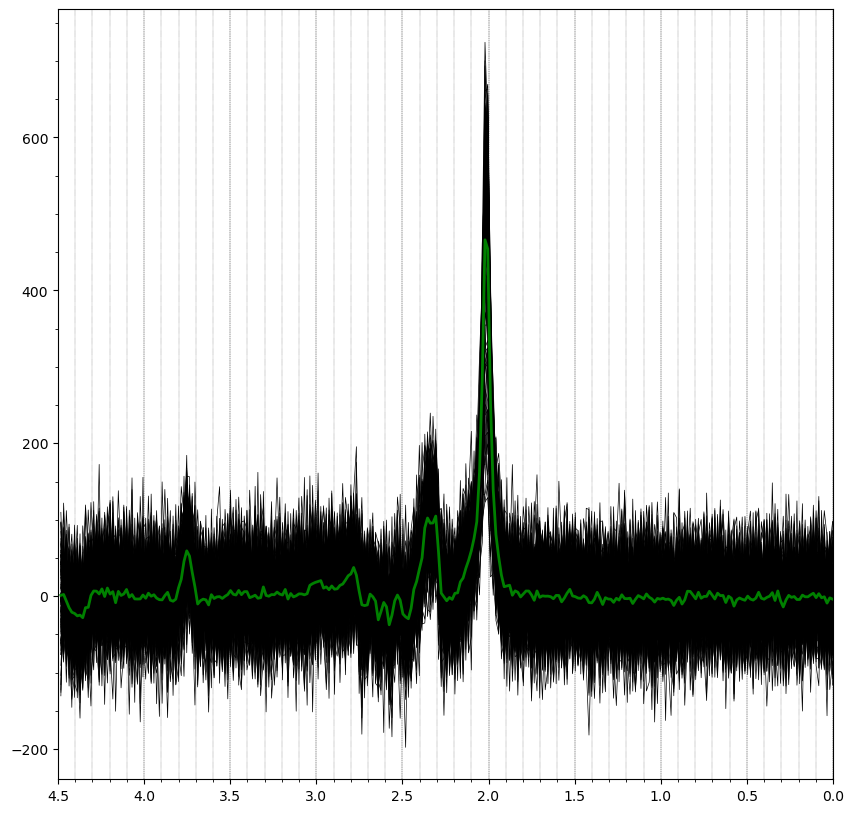

In [125]:
def generate_dataset(directions, noisevar, defined_values):
    ignore_metabs = ['Tau', 'Scyllo', 'PE', 'PCr', 'PCh', 'NAAG', 'Lac', 'Ins', 'Gln', 'Glc', 'GSH', 'GPC', 'Cr', 'Asp', 'Asc', 'Ala']
    basis.ignore = ignore_metabs

    mrs_list, vm_obj, ground_truth = syn.synthetic_spectra_from_model(
        'dtmrs_model.py',
        directions,
        'basis',
        ignore=ignore_metabs,
        metab_groups=None,
        ind_scaling=None,
        concentrations=None,
        baseline_order=0,
        baseline_ppm=None,
        defined_vals=defined_vals,
        param_noise=None,
        param_rel_noise=None,
        noisecovariance=[[noisevar]],
        bandwidth=2000,
        points=1024
    )

    _ = splot.plot_spectra(mrs_list)
    truth_df = pd.Series(ground_truth, index=vm_obj.free_names)
    return mrs_list, truth_df

from fsl_mrs.utils.synthetic.synthetic_from_basis import standardConcentrations
std_concs = standardConcentrations(basis.names)

defined_vals = {
    'gamma_0': 16,
    'sigma_0': 0
}
for name, conc in zip(basis.names, std_concs):
    defined_vals[f'conc_{name}_c_amp'] = conc
    defined_vals.update(gen_metabolite_tensor_params(name))

mrs_list_6, truth_df_6 = generate_dataset(b_6_dir, 200, defined_vals)
mrs_list_60, truth_df_60 = generate_dataset(b_60_dir, 2000, defined_vals)
assert truth_df_6.equals(truth_df_60)

In [126]:
from fsl_mrs.dynamic import dynMRS

fit_args = {'model': 'lorentzian',
            'ppmlim': (0.2, 4.2),
            'baseline_order': 0}

# Create the dynamic fitting object
dyn_6 = dynMRS(mrs_list_6, b_6_dir, config_file='dtmrs_model.py', rescale=False, **fit_args)

# Initialise the fit.
init_6 = dyn_6.initialise(verbose=True, indiv_init='mean')

dyn_res_6 = dyn_6.fit(init=init_6, verbose=True, method='Newton')

Init done in 3.5649499893188477 seconds.
Start fitting
...completed in 3.3656089305877686 seconds.
Collect results
...completed in 0.3252720832824707 seconds.


In [127]:
# Create the dynamic fitting object
dyn_60 = dynMRS(mrs_list_60, b_60_dir, config_file='dtmrs_model.py', rescale=False, **fit_args)

# Initialise the fit.
init_60 = dyn_60.initialise(verbose=True, indiv_init='mean')

dyn_res_60 = dyn_60.fit(init=init_60, verbose=True, method='Newton')

Init done in 34.109156131744385 seconds.
Start fitting
...completed in 106.32469511032104 seconds.
Collect results
...completed in 3.0147488117218018 seconds.


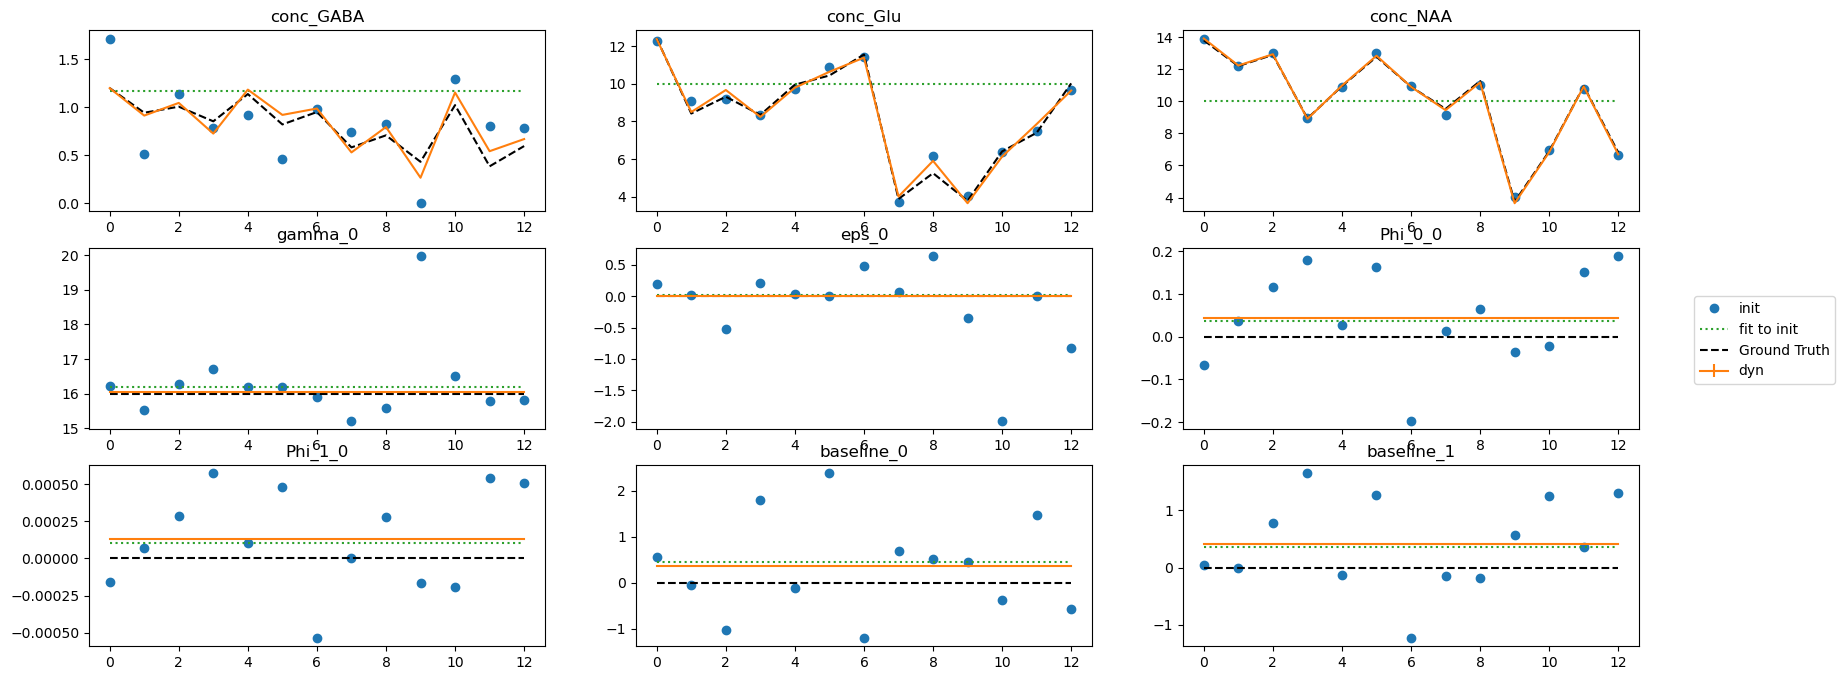

In [128]:
fig = dyn_res_6.plot_mapped(tvals=np.arange(b_6_dir.shape[0]), fit_to_init=True, ground_truth=truth_df_6.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

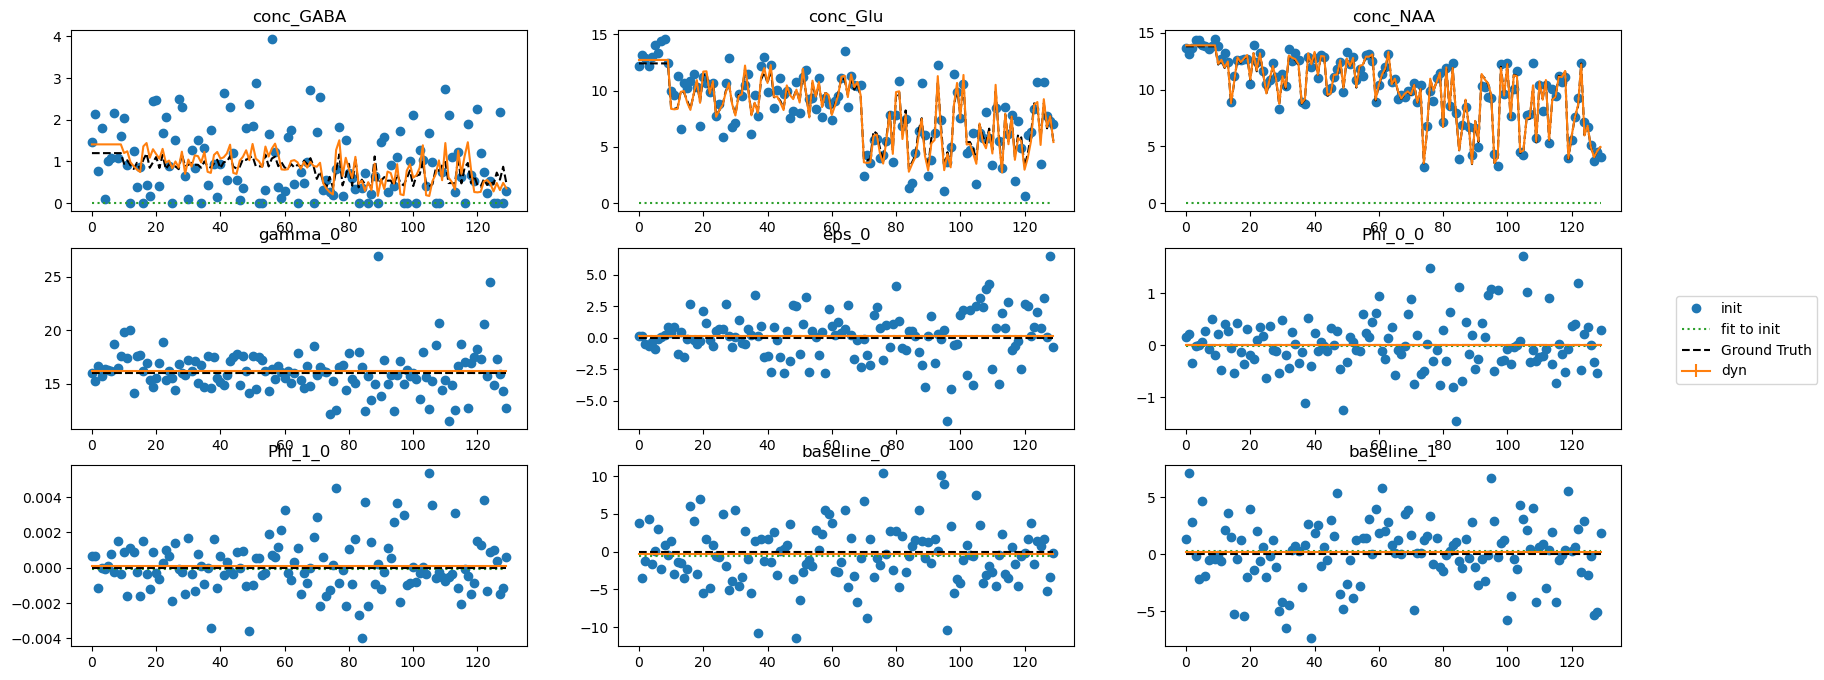

In [129]:
fig = dyn_res_60.plot_mapped(tvals=np.arange(b_60_dir.shape[0]), fit_to_init=True, ground_truth=truth_df_60.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

In [132]:
comp_df = pd.concat([truth_df_60.drop('sigma_0'), dyn_res_6.dataframe_free.T[0], dyn_res_60.dataframe_free.T[0]], axis=1, keys=['true', '6_dir', '60_dir'])
comp_df.filter(axis=0, regex='(Glu_)|(GABA_)|(NAA_)')

,true,6_dir,60_dir
conc_GABA_c_amp,1.200000,1.199282,1.409728
conc_GABA_c_Dxx,0.241332,0.272475,0.158893
conc_GABA_c_Dyy,0.215847,0.095298,0.176270
conc_GABA_c_Dzz,0.255268,0.324672,0.611765
conc_GABA_c_Dxy,0.110970,0.066518,0.102520
conc_GABA_c_Dxz,0.079244,0.205085,0.211857
conc_GABA_c_Dyz,-0.154388,-0.151492,-0.149607
conc_Glu_c_amp,12.410000,12.381271,12.717040
conc_Glu_c_Dxx,0.387972,0.376216,0.417670
conc_Glu_c_Dyy,0.096689,0.068087,0.098650


## Analyse results

In [133]:
def frame_to_mat(df, metab):
    Dxx = df.filter(regex=f'conc_{metab}_c_Dxx$').to_numpy().squeeze()
    Dyy = df.filter(regex=f'conc_{metab}_c_Dyy$').to_numpy().squeeze()
    Dzz = df.filter(regex=f'conc_{metab}_c_Dzz$').to_numpy().squeeze()
    Dxy = df.filter(regex=f'conc_{metab}_c_Dxy$').to_numpy().squeeze()
    Dxz = df.filter(regex=f'conc_{metab}_c_Dxz$').to_numpy().squeeze()
    Dyz = df.filter(regex=f'conc_{metab}_c_Dyz$').to_numpy().squeeze()
    return np.asarray([[Dxx, Dxy, Dxz], [Dxy, Dyy, Dyz], [Dxz, Dyz, Dzz]])

def calc_eig(dt_metabs):
    eig_metabs = {}
    eigv_metabs = {}
    for metab in dt_metabs:
        w,v = np.linalg.eig(dt_metabs[metab])
        eig_metabs.update({metab: w})
        eigv_metabs.update({metab: v})
    return eig_metabs, eigv_metabs

def calc_derieved_params(results_frame):
    dt_metabs = {}
    for metab in mrs_list_60[0].names:
        dt_metabs.update({metab: frame_to_mat(results_frame, metab)})
    vals, vecs = calc_eig(dt_metabs)

    results_df = pd.DataFrame(vals).T.rename(columns={0:'lambda_1',1:'lambda_2',2:'lambda_3'})
    results_df['MD'] = results_df.sum(axis=1)/3
    results_df['FA'] =results_df[['lambda_1','lambda_2','lambda_3']].subtract(results_df['MD'],axis=0).pow(2).sum(axis=1)\
        .divide(results_df[['lambda_1','lambda_2','lambda_3']].pow(2).sum(axis=1)).pow(0.5)\
        .multiply(np.sqrt(3/2))
    return results_df

derived_true = calc_derieved_params(pd.Series(defined_vals)) 

derived_6 = calc_derieved_params(dyn_res_6.dataframe_free) 

derived_60 = calc_derieved_params(dyn_res_60.dataframe_free) 


print(derived_true.filter(items=['NAA', 'Glu', 'GABA'],axis=0))
print(derived_6.filter(items=['NAA', 'Glu', 'GABA'],axis=0))
print(derived_60.filter(items=['NAA', 'Glu', 'GABA'],axis=0))

      lambda_1  lambda_2  lambda_3        MD        FA
NAA   0.476763  0.073543  0.035282  0.195196  0.875866
Glu   0.485098  0.246171  0.036659  0.255976  0.712810
GABA  0.002656  0.316533  0.393258  0.237482  0.710046
      lambda_1  lambda_2  lambda_3        MD        FA
NAA   0.488431  0.077519  0.038808  0.201586  0.869991
Glu   0.468450  0.255533  0.025853  0.249945  0.717642
GABA  0.518435  0.234805 -0.060796  0.230815  0.876473
      lambda_1  lambda_2  lambda_3        MD        FA
NAA   0.476531  0.074157  0.038447  0.196378  0.870956
Glu   0.521178  0.285230  0.027159  0.277856  0.719597
GABA  0.715848 -0.037739  0.268819  0.315643  0.857372


In [134]:
print((derived_true.MD - derived_6.MD).pow(2))
print((derived_true.MD - derived_60.MD).pow(2))


GABA    0.000044
Glu     0.000036
NAA     0.000041
Name: MD, dtype: float64
GABA    0.006109
Glu     0.000479
NAA     0.000001
Name: MD, dtype: float64


### Perfect initialisation

Start fitting
...completed in 75.03664112091064 seconds.
Collect results
...completed in 2.9025230407714844 seconds.


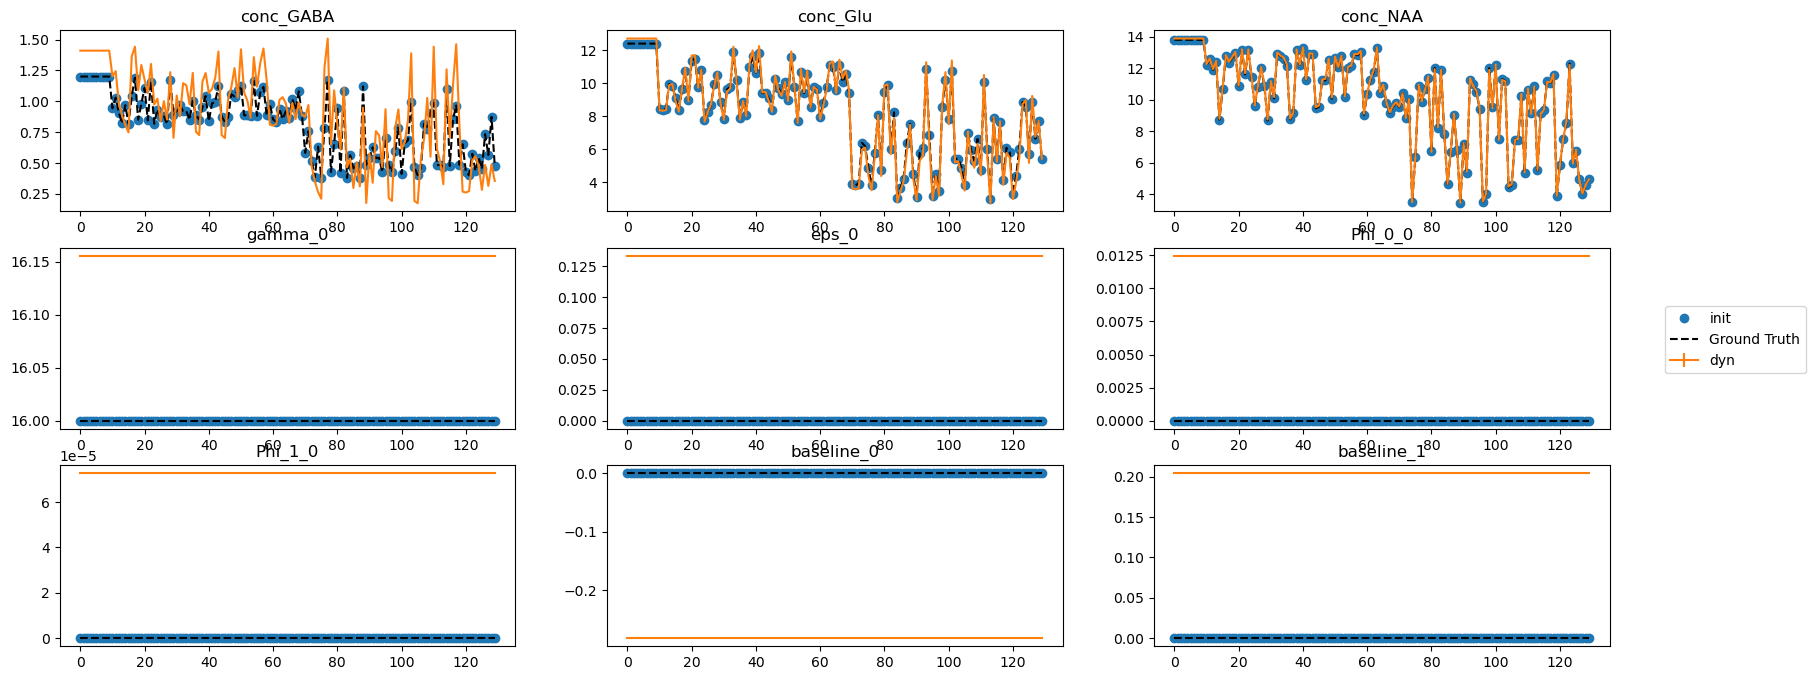

In [135]:
dyn_res_perfect = dyn_60.fit(x0=truth_df_60.drop('sigma_0').to_numpy(), verbose=True, method='Newton')
fig = dyn_res_perfect.plot_mapped(tvals=np.arange(b_60_dir.shape[0]), fit_to_init=False, ground_truth=truth_df_60.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

In [136]:
derived_perfect_init = calc_derieved_params(dyn_res_perfect.dataframe_free) 


In [139]:
100*(derived_perfect_init-derived_true)/derived_true

,lambda_1,lambda_2,lambda_3,MD,FA
GABA,26847.400282,-111.922937,-31.644369,32.909225,20.749022
Glu,7.437883,15.866211,-25.912160,8.547674,0.952056
NAA,-0.048699,0.834167,8.967486,0.605416,-0.560501


In [140]:
100*(derived_60-derived_true)/derived_true

,lambda_1,lambda_2,lambda_3,MD,FA
GABA,26847.934326,-111.922700,-31.643131,32.912006,20.748845
Glu,7.437753,15.866177,-25.913158,8.547533,0.952108
NAA,-0.048664,0.834280,8.967787,0.605477,-0.560522


In [141]:
100*(derived_6-derived_true)/derived_true

,lambda_1,lambda_2,lambda_3,MD,FA
GABA,19416.378429,-25.819693,-115.459678,-2.807643,23.439039
Glu,-3.431885,3.802975,-29.477390,-2.355979,0.677823
NAA,2.447353,5.405517,9.992049,3.273443,-0.670724


In [ ]:
comp_df = pd.concat([truth_df.drop('sigma_0'), dyn_res.dataframe_free.T[0], dyn_res.init_free_dataframe, dyn_res_perfect.dataframe_free.T[0]], axis=1, keys=['true', 'dyn', 'init', 'perfect'])
comp_df.filter(axis=0, regex='GABA_')

,true,dyn,init,perfect
conc_GABA_c_amp,1.200000,1.409381,1.681353,1.410787
conc_GABA_c_Dxx,0.292239,1.258689,0.000000,1.231120
conc_GABA_c_Dyy,0.246985,0.241407,0.000000,0.249856
conc_GABA_c_Dzz,0.126446,0.539415,0.000000,0.546557
conc_GABA_c_Dxy,0.091153,0.378539,0.000000,0.346479
conc_GABA_c_Dxz,0.015072,-0.299940,0.000000,-0.288784
conc_GABA_c_Dyz,-0.055012,0.091268,0.000000,0.115081
